In [2]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

In [3]:
%matplotlib inline
sys.path.append("..")
import wavelet_transform.utils.training_data as train
import wavelet_transform.postprocess.plotting as plot

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

### Set pararmeters for bubble dynamics model

In [26]:
pac = -5E5                                  # the amplitude of the sine wave in Pa
frequency = 5E5                  # insonation frequency (Hz)
no_cycle = 20                               # no. of cycles of the sine wave
sampling_rate = 500E6      # sampling rate to generate the time vector
real_sampling_rate = 25E6
tstep = 1. / sampling_rate
tmax = no_cycle / frequency
time = np.arange(0., tmax, tstep) # time vector for computing the sine wave, in seconds
t_plot = time

R_init = 10E-6                  # initial bubble radius in meters
Rdot_init = 0                   # initial bubble's wall velocity in m/s

r_measure = 50*R_init           # distance from the centre of bubble which radiated pressure (acoustic emission from bubble) is calculated over time 

std_noise = 0.001

wavelet = "db20"
levels = 4
mode = "symmetric"

fft_lim = 10 * frequency  # increase value to view more of the fft plots

### Training data

Run bubble dynamics over a range of frequencies and intensities to generate a larger array of training data.

In [27]:
wpt_df = None
for frequency in [i * 1E5 for i in range(8, 10)]:
    for pac in [-i * 1E4 for i in range(1, 20)]:
        data = train.generate_data(R_init, Rdot_init, frequency, pac, time, tstep, r_measure)
        if max(data) > 70 or np.isnan(data).any():  # filter out failed dynamics model computations
            continue
        data = (data - np.mean(data))/np.std(data)
        data += np.random.normal(0, std_noise, size=len(data))

        # data = np.random.normal(0, std_noise, size=len(data))

        # plt.plot(data)
        # plt.title(f"Frequency: {frequency}, pac: {pac}")
        # plt.show()
        step = int(sampling_rate/real_sampling_rate)
        training_data = train.generate_training_data(
            data[::step], levels, wavelet, mode, min_energy=0.005, include_low_energy=0
        )
        if wpt_df is None:
            wpt_df = training_data
        else:
            wpt_df = pd.concat([wpt_df, training_data], ignore_index=True)

# Add noise samples
add_noise = .1  # 1/4 of the dataset is noise
n = wpt_df.shape[0]
n_noise_samples = int(n * add_noise / (1 - add_noise))
for i in range(n_noise_samples):
    noise = np.random.normal(0, std_noise, size=len(data))
    training_data = train.generate_training_data(noise[::step], levels, wavelet, mode)
    wpt_df= pd.concat([wpt_df, training_data], ignore_index=True)

nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 2/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16
nodes kept: 16/16


### Training

Train fuzzy c-means on the generated data

In [28]:
from sklearn.preprocessing import StandardScaler
import skfuzzy as fuzz

# Get data
wpt_df
classifying_metrics = ["log energy", "crest factor", "spectral entropy"]
data_train = wpt_df[classifying_metrics]

# Standardise data
scaler = StandardScaler()
data_train_normalised = scaler.fit_transform(data_train)

# Parameters for Fuzzy C-means
no_clusters = 4
m = 2
error = 1e-6

# Fuzzy C-Means clustering
cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
    data_train_normalised.T,
    c=no_clusters,
    m=m,
    error=error,
    maxiter=100,
)
print("number of iterations:", p)
# Cluster centres
centers = scaler.inverse_transform(cntr)
print("centers:", centers)
# Membership matrix
membership_matrix = u.T

# Hard cluster assignments
labels = np.argmax(membership_matrix, axis=1)
for i in range(no_clusters):
    print(f"label {i} count:", list(labels).count(i))

# membership_results = pd.DataFrame()
# for i, membership in enumerate(membership_matrix):
#     membership_results.loc[i, "hard assignment"] = labels[i]
#     for j in range(no_clusters):
#         membership_results.loc[i, f"membership {j}"] = membership[j]

# membership_results.head()

number of iterations: 45
centers: [[ 0.86803927  1.60424562  4.03066896]
 [-6.00670126  2.24515847  5.92710579]
 [ 0.35045001  2.06752225  4.84893514]
 [-6.03604109  2.93078241  5.98461302]]
label 0 count: 57
label 1 count: 82
label 2 count: 19
label 3 count: 46


Plotting clustering results

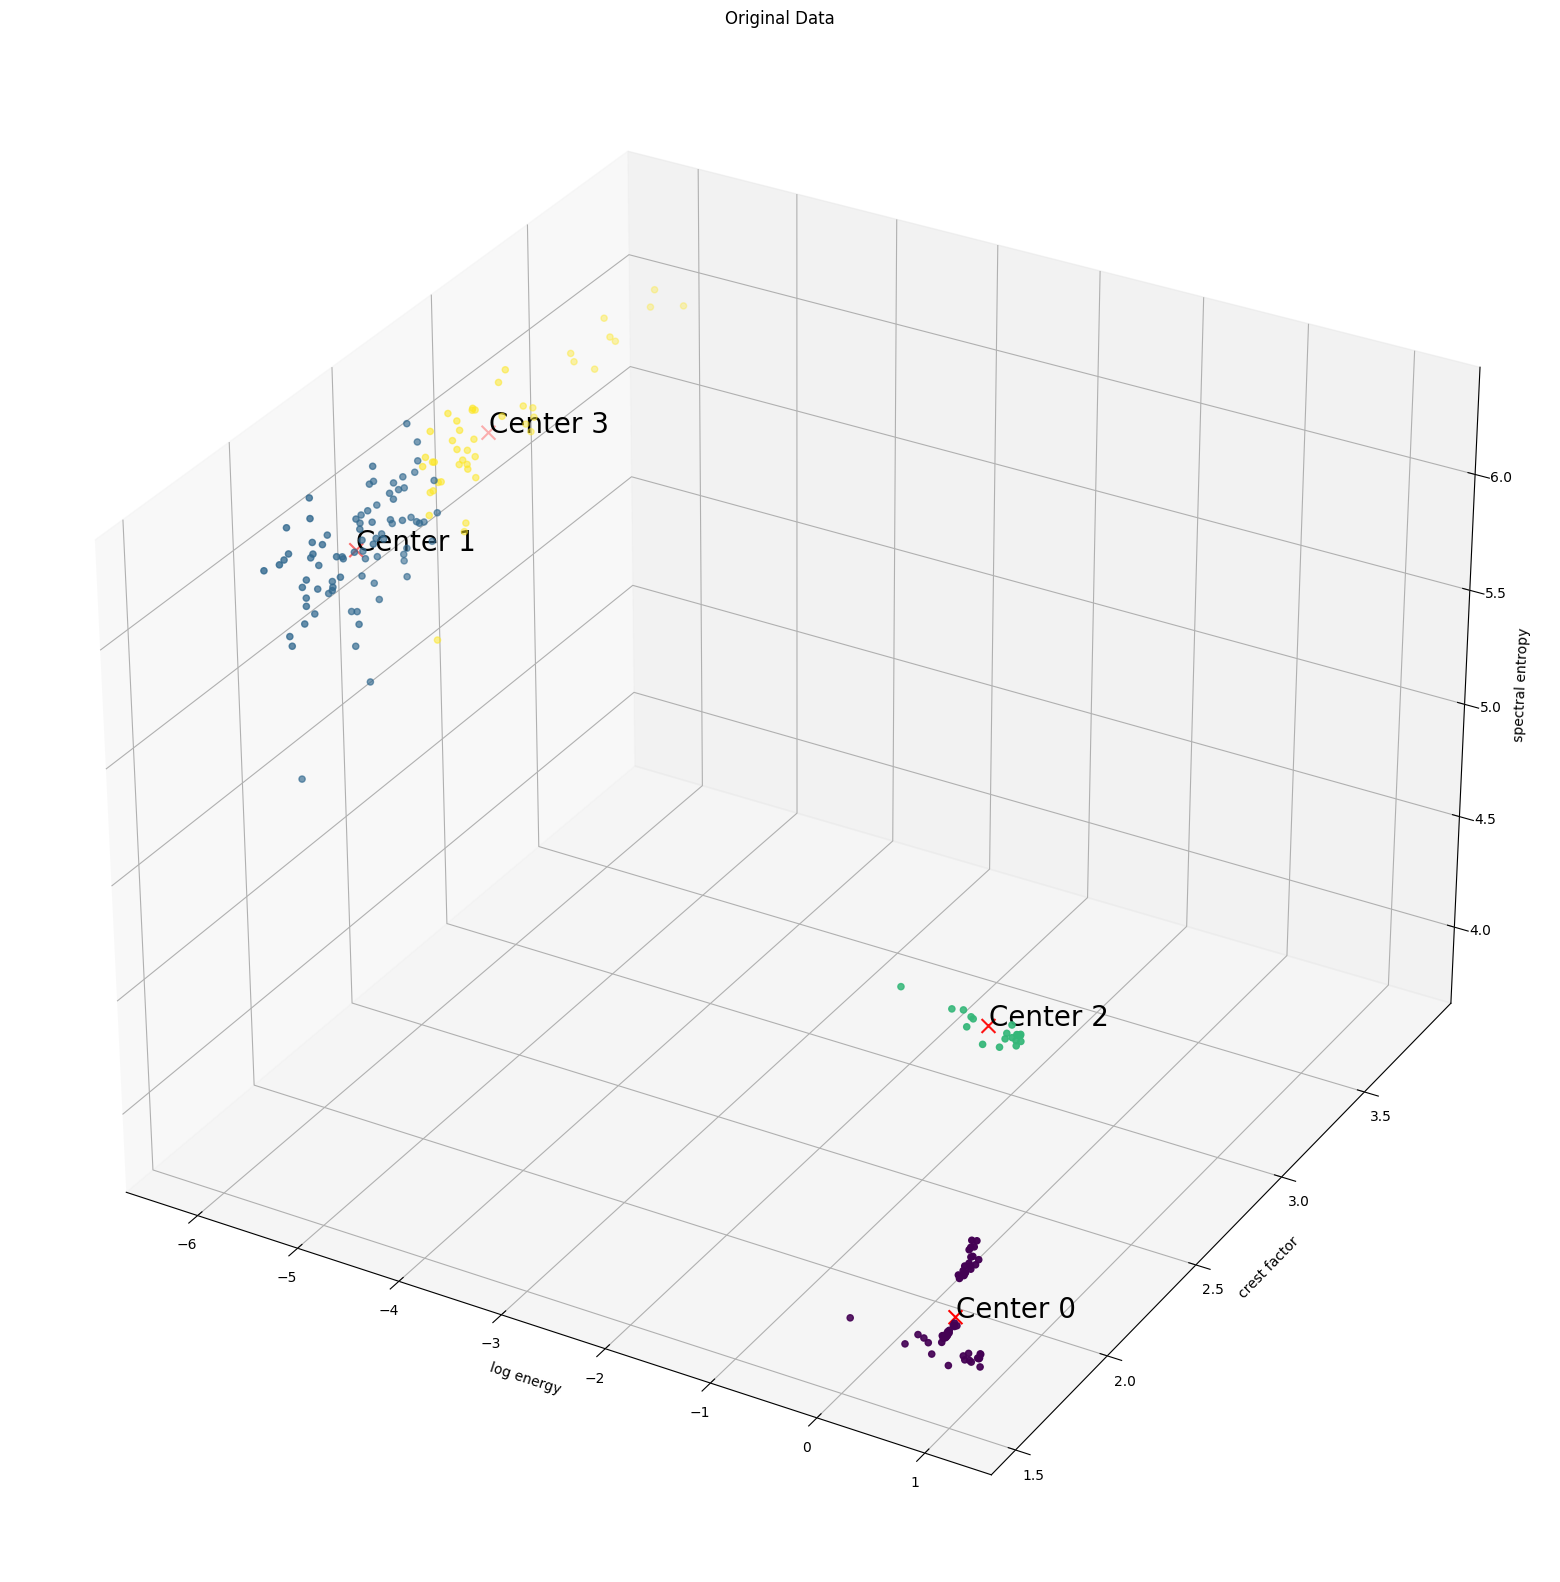

In [29]:
fig = plt.figure(figsize=(20, 20))
ax = fig.add_subplot(111, projection="3d")

title = "Original Data"

data_scatter = data_train.values.tolist()
centers_scatter = centers
color_map_labels = labels

# Plot data points
data_plot = ax.scatter(
    [point[0] for point in data_scatter],
    [point[1] for point in data_scatter],
    [point[2] for point in data_scatter],
    c=color_map_labels
)

# Plot cluster centers after data points
center_plot = ax.scatter(
    centers_scatter[:, 0],
    centers_scatter[:, 1],
    centers_scatter[:, 2],
    c="red",
    marker="x",
    s=100,
)

# Annotate cluster centers with their positions
for i, center in enumerate(centers_scatter):
    ax.text(center[0], center[1], center[2], f'Center {i}', color='black', fontsize=20)

ax.set_xlabel(data_train.columns[0])
ax.set_ylabel(data_train.columns[1])
ax.set_zlabel(data_train.columns[2])
ax.set_title(title)

plt.show()

### Classifying new data points

dynamics is inconsistent
clustering works better with fewer levels
need better standardisation of data

nodes kept: 16/16


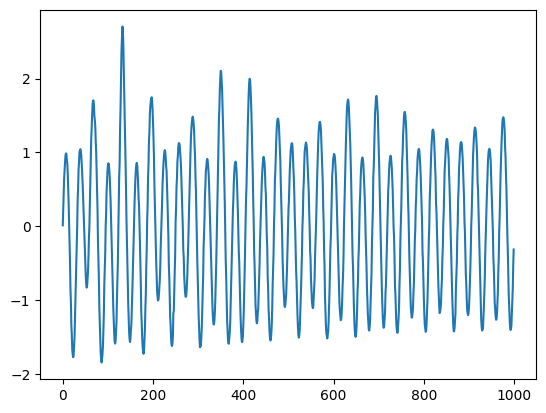

In [35]:
frequency = 8E5
pac = -2E5

min_energy = 0  # Only nodes with energy at least min_energy * total_energy will be considered

data = train.generate_data(R_init, Rdot_init, frequency, pac, time, tstep, r_measure)
data = (data - np.mean(data)) / np.std(data)
data += np.random.normal(0, std_noise, len(data))
data = data[::step]

new_wpt_df, new_tr_ob = train.generate_training_data(
    data, 
    levels,
    wavelet, 
    mode,
    min_energy=min_energy,
    include_tr_ob=True
)

new_wpt_df.head()

plt.plot(data)
plt.show()

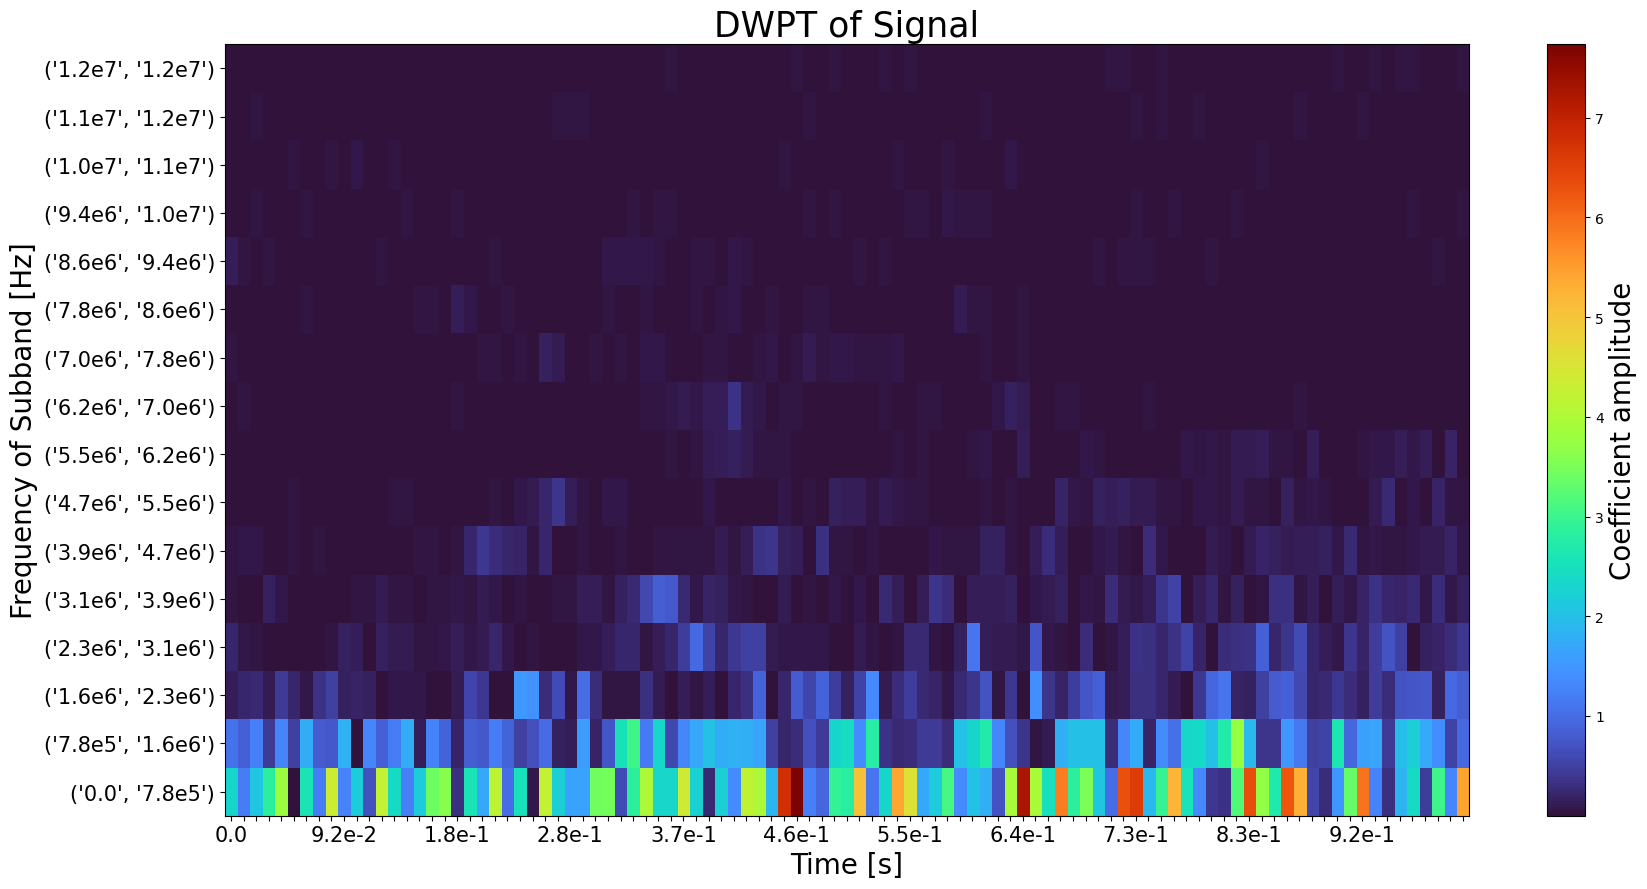

In [31]:
new_tr_ob.calc_frequencies(real_sampling_rate)
plot.heisenberg(new_tr_ob)

In [36]:
# New testing data from signal
new_entry = new_wpt_df[classifying_metrics]

# Standardize the new entry using the same scaler
new_entry_normalized = scaler.transform(new_entry)

# Predict membership using the cluster centers and membership matrix
new_u, *_ = fuzz.cluster.cmeans_predict(
    new_entry_normalized.T,
    cntr,
    m=m,
    error=error,
    maxiter=100,
)

new_membership_matrix = new_u.T
# Convert membership to hard cluster assignment
new_labels = np.argmax(new_u, axis=0)

# Display the predicted results
print("Predicted hard cluster assignment:", new_labels)

membership_results = pd.DataFrame()
for i, membership in enumerate(new_membership_matrix):
    membership_results.loc[i, "hard assignment"] = new_labels[i]
    for j in range(no_clusters):
        membership_results.loc[i, f"membership {j}"] = membership[j]

membership_results

Predicted hard cluster assignment: [0 0 3 3 3 3 1 3 1 1 1 3 1 1 1 1]


,hard assignment,membership 0,membership 1,membership 2,membership 3
0,0.0,0.920391,0.007529,0.067056,0.005024
1,0.0,0.993780,0.000841,0.004811,0.000568
2,3.0,0.078580,0.309739,0.204411,0.407270
3,3.0,0.160734,0.239381,0.219173,0.380712
4,3.0,0.134905,0.236798,0.200293,0.428004
5,3.0,0.066647,0.194808,0.133263,0.605282
6,1.0,0.060638,0.550684,0.174593,0.214085
7,3.0,0.046703,0.304048,0.115346,0.533903
8,1.0,0.047640,0.418255,0.123924,0.410181
9,1.0,0.122594,0.483387,0.256084,0.137935


### Reconstructing by cluster

Reconstructed nodes by group:


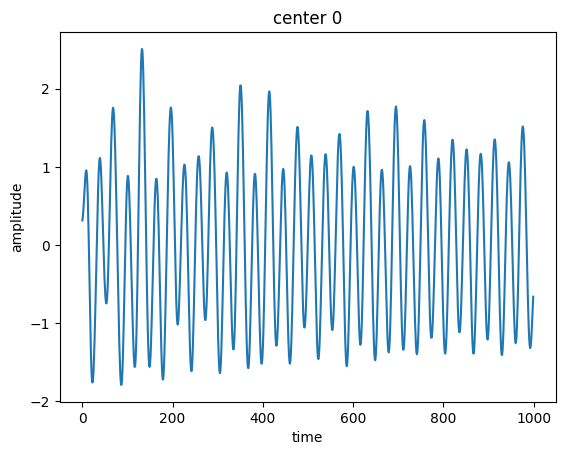

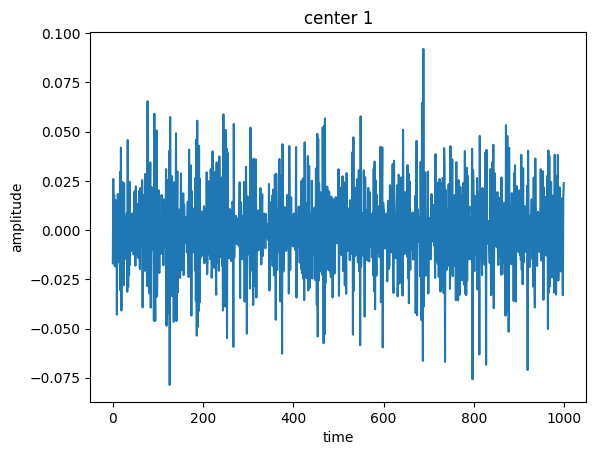

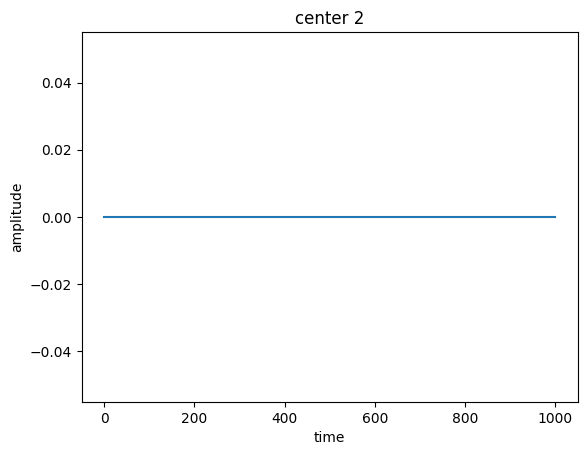

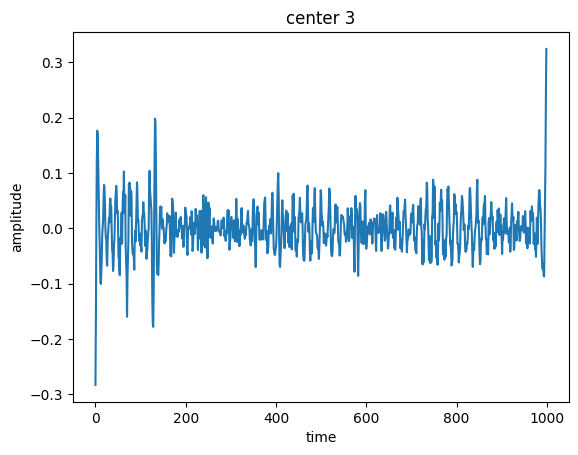

In [37]:
# Sum all reconstructions belonging to the same group
plot.plot_reconstructions_by_group(new_tr_ob, new_labels, no_clusters, order="freq")

### Plot nodes

Plot each node in the test data set alongside its membership values. Filter by the centre the node is assigned to.

0.08673083400506892


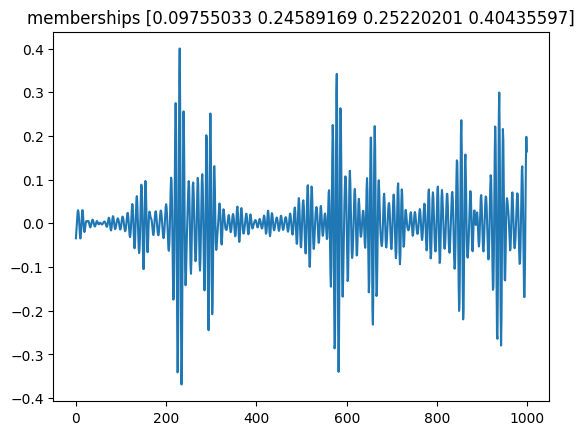

0.26359562866063374


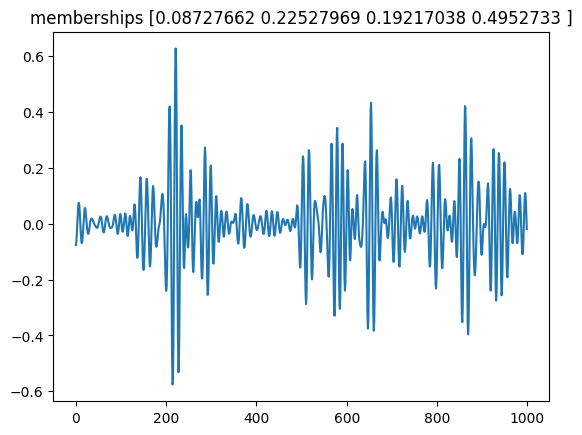

0.0029071590422632596


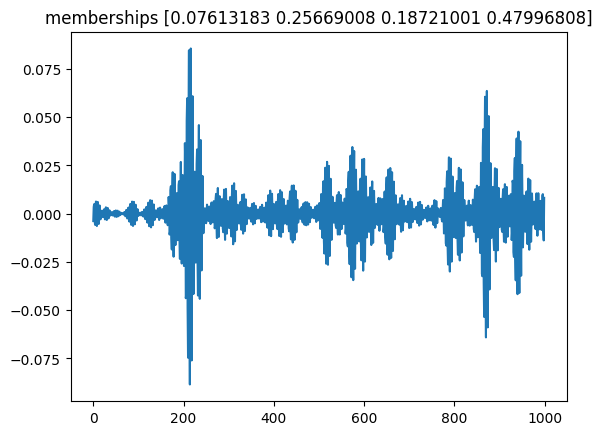

0.03820471867306312


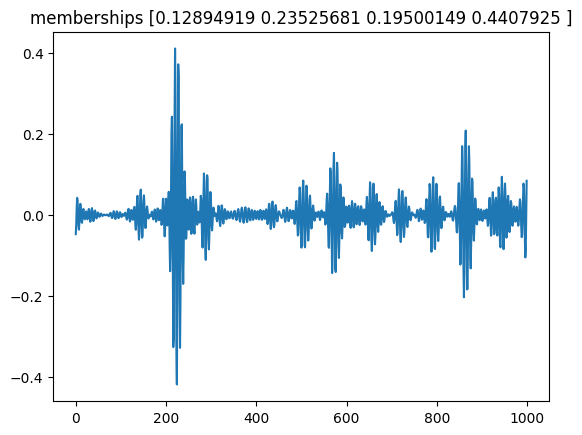

0.01553290130141051


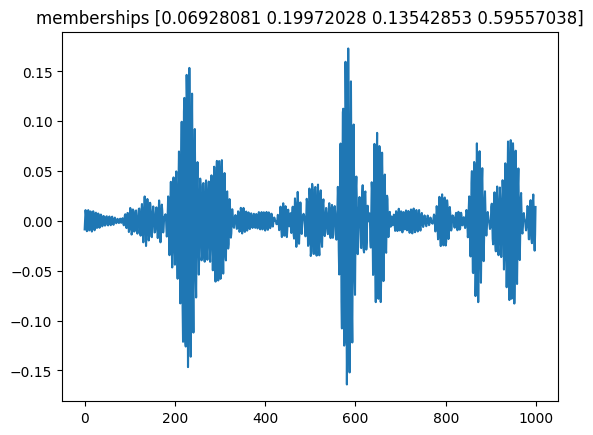

0.0004494174791932727


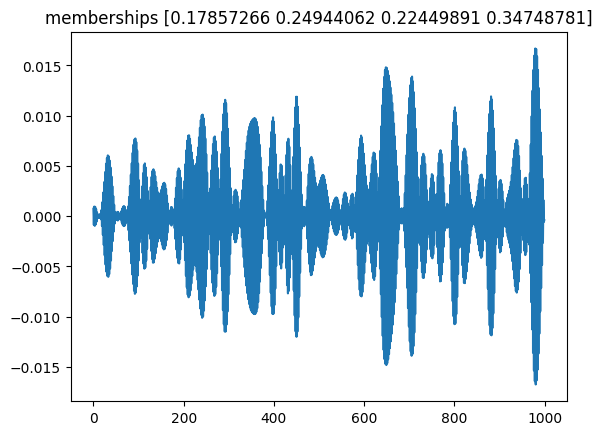

0.0004714594658164744


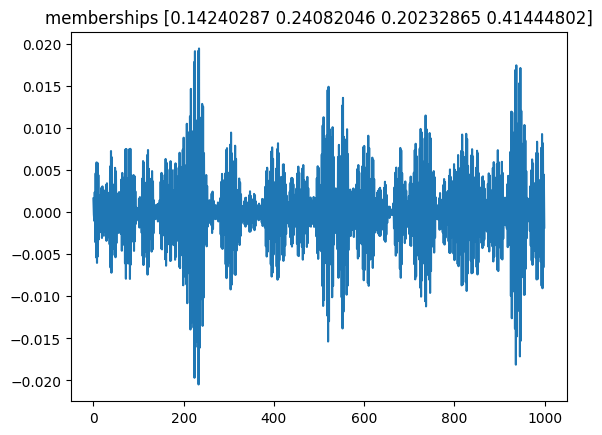

0.001271411554928802


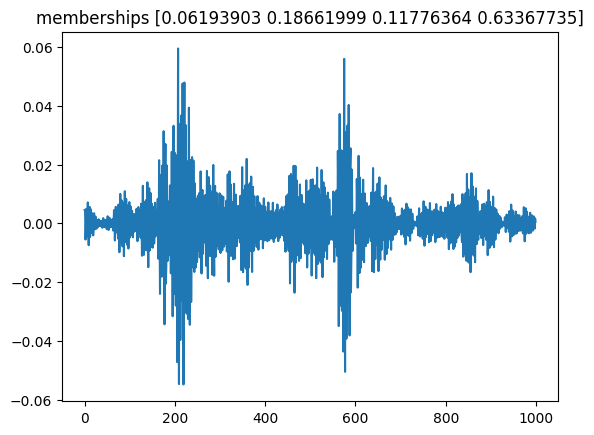

In [34]:
import wavelet_transform.wpt.inverse_transform as inv
run = True
if run is True:
    plot_centres = [3]
    for i, (node, assignment) in enumerate(zip(new_tr_ob.get_level(), new_labels)): 
        if assignment in plot_centres:
            print(node.energy)
            rec = inv.inv_dwpt(new_tr_ob, levels, nodes=node)
            plt.plot(rec)
            plt.title(f"memberships {new_membership_matrix[i]}")
            plt.show()